Cargando datos de entrenamiento...
Found 7390 files belonging to 37 classes.
Using 5912 files for training.

Cargando datos de validación...
Found 7390 files belonging to 37 classes.
Using 1478 files for validation.

¡Se detectaron 37 razas distintas automáticamente!
Algunas de las clases son: ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair']...


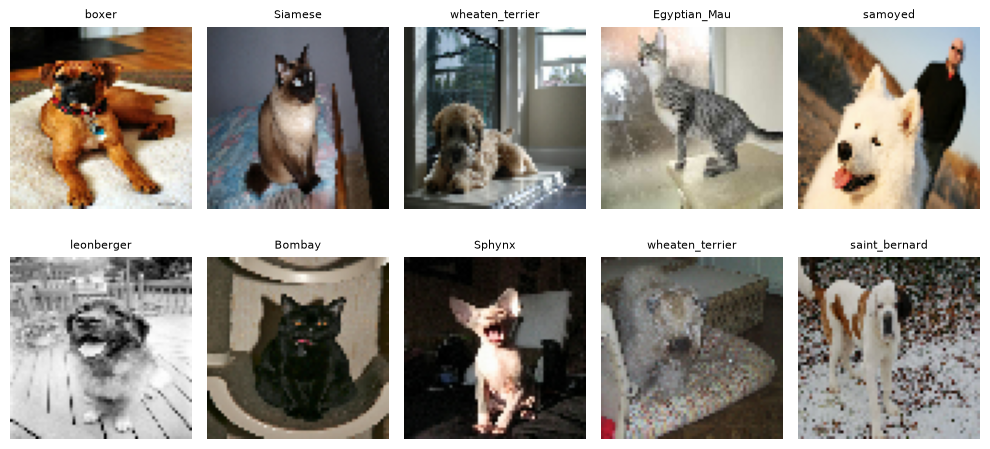

In [9]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

# 1. DEFINICIÓN DE VARIABLES Y RUTA
# Apuntamos a la carpeta que ya contiene todas las razas separadas
CARPETA_DATOS = '../dataset/oxford_procesado_todas' 

IMG_SIZE = (64, 64) 
BATCH_SIZE = 32
SEMILLA = 42 

print("Cargando datos de entrenamiento...")
# Keras detectará automáticamente las clases basándose en las carpetas
train_dataset = tf.keras.utils.image_dataset_from_directory(
    CARPETA_DATOS,
    validation_split=0.2, 
    subset="training",
    seed=SEMILLA,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("\nCargando datos de validación...")
val_dataset = tf.keras.utils.image_dataset_from_directory(
    CARPETA_DATOS,
    validation_split=0.2,
    subset="validation",
    seed=SEMILLA,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Keras guardó los nombres de las carpetas en 'class_names'
class_names = train_dataset.class_names
NUM_CLASES = len(class_names)
print(f"\n¡Se detectaron {NUM_CLASES} razas distintas automáticamente!")
print(f"Algunas de las clases son: {class_names[:5]}...")

# 2. PREPROCESAMIENTO: Normalización (escala de 0 a 1)
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
val_dataset = val_dataset.map(lambda x, y: (normalization_layer(x), y))

# 3. VISUALIZACIÓN EXPLORATORIA
plt.figure(figsize=(10, 5))
for images, labels in train_dataset.take(1): 
    for i in range(10): 
        ax = plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy()) 
        # Ponemos el nombre de la raza detectada
        plt.title(class_names[labels[i]], fontsize=8) 
        plt.axis("off")
plt.tight_layout()
plt.show()

In [10]:
# 4. DISEÑO DE LA ARQUITECTURA MLP (Multiclase)
print("\nConstruyendo el modelo MLP para clasificación de múltiples razas...")

modelo_mlp = tf.keras.Sequential([
    # Aplanamos la imagen de 2D a 1D
    tf.keras.layers.Flatten(input_shape=(64, 64, 3)),
    
    # Capas ocultas un poco más grandes porque aprender 30+ razas es más difícil
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.3), 
    
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    
    # Capa de salida: 1 neurona POR CADA RAZA, activación 'softmax' (Multiclase)
    tf.keras.layers.Dense(NUM_CLASES, activation='softmax')
])

# Mostramos un resumen de las capas
modelo_mlp.summary()

# 5. COMPILACIÓN Y ENTRENAMIENTO
print("\nCompilando el modelo...")
modelo_mlp.compile(
    optimizer='adam', 
    # Usamos crossentropy categórico porque hay múltiples clases
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy'] 
)

# Usamos 15 épocas porque al ser muchas razas le tomará más tiempo aprender
EPOCAS = 15 

print("\nIniciando el entrenamiento (esto puede tomar unos minutos)...")
historial = modelo_mlp.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCAS
)

print("\n¡Entrenamiento completado!")


Construyendo el modelo MLP para clasificación de múltiples razas...


c:\Users\lilbe\OneDrive\Escritorio\mi proyecto\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,432,805 (24.54 MB)

 Trainable params: 6,432,805 (24.54 MB)

 Non-trainable params: 0 (0.00 B)


Compilando el modelo...

Iniciando el entrenamiento (esto puede tomar unos minutos)...
Epoch 1/15


c:\Users\lilbe\OneDrive\Escritorio\mi proyecto\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


185/185 ━━━━━━━━━━━━━━━━━━━━ 16s 79ms/step - accuracy: 0.0360 - loss: 3.9348 - val_accuracy: 0.0528 - val_loss: 3.5379
Epoch 2/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.0403 - loss: 3.5696 - val_accuracy: 0.0203 - val_loss: 3.6258
Epoch 3/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.0348 - loss: 3.5768 - val_accuracy: 0.0501 - val_loss: 3.5482
Epoch 4/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 12s 65ms/step - accuracy: 0.0364 - loss: 3.5956 - val_accuracy: 0.0440 - val_loss: 3.5657
Epoch 5/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - accuracy: 0.0433 - loss: 3.5706 - val_accuracy: 0.0521 - val_loss: 3.5329
Epoch 6/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.0438 - loss: 3.5311 - val_accuracy: 0.0514 - val_loss: 3.4981
Epoch 7/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.0445 - loss: 3.5216 - val_accuracy: 0.0636 - val_loss: 3.4642
Epoch 8/15
185/185 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.0506 - loss: 3.5016 - val_accurac

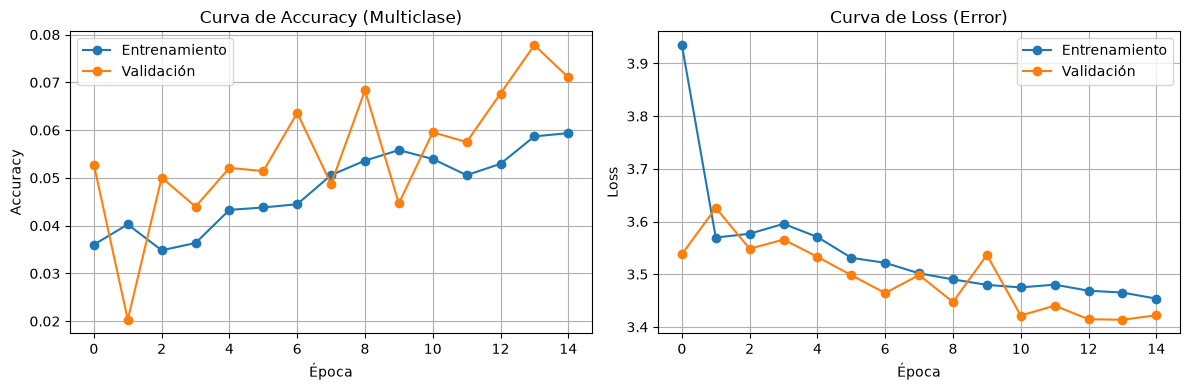


Generando predicciones en el set de validación...

--- REPORTE DE CLASIFICACIÓN ---
                            precision    recall  f1-score   support

                Abyssinian       0.00      0.00      0.00        32
                    Bengal       0.00      0.00      0.00        36
                    Birman       0.00      0.00      0.00        31
                    Bombay       0.11      0.62      0.19        40
         British_Shorthair       0.00      0.00      0.00        46
              Egyptian_Mau       0.15      0.14      0.15        35
                Maine_Coon       0.00      0.00      0.00        38
                   Persian       0.00      0.00      0.00        26
                   Ragdoll       0.08      0.13      0.10        39
              Russian_Blue       0.00      0.00      0.00        49
                   Siamese       0.00      0.00      0.00        44
                    Sphynx       0.07      0.03      0.04        34
          american_bulldog    

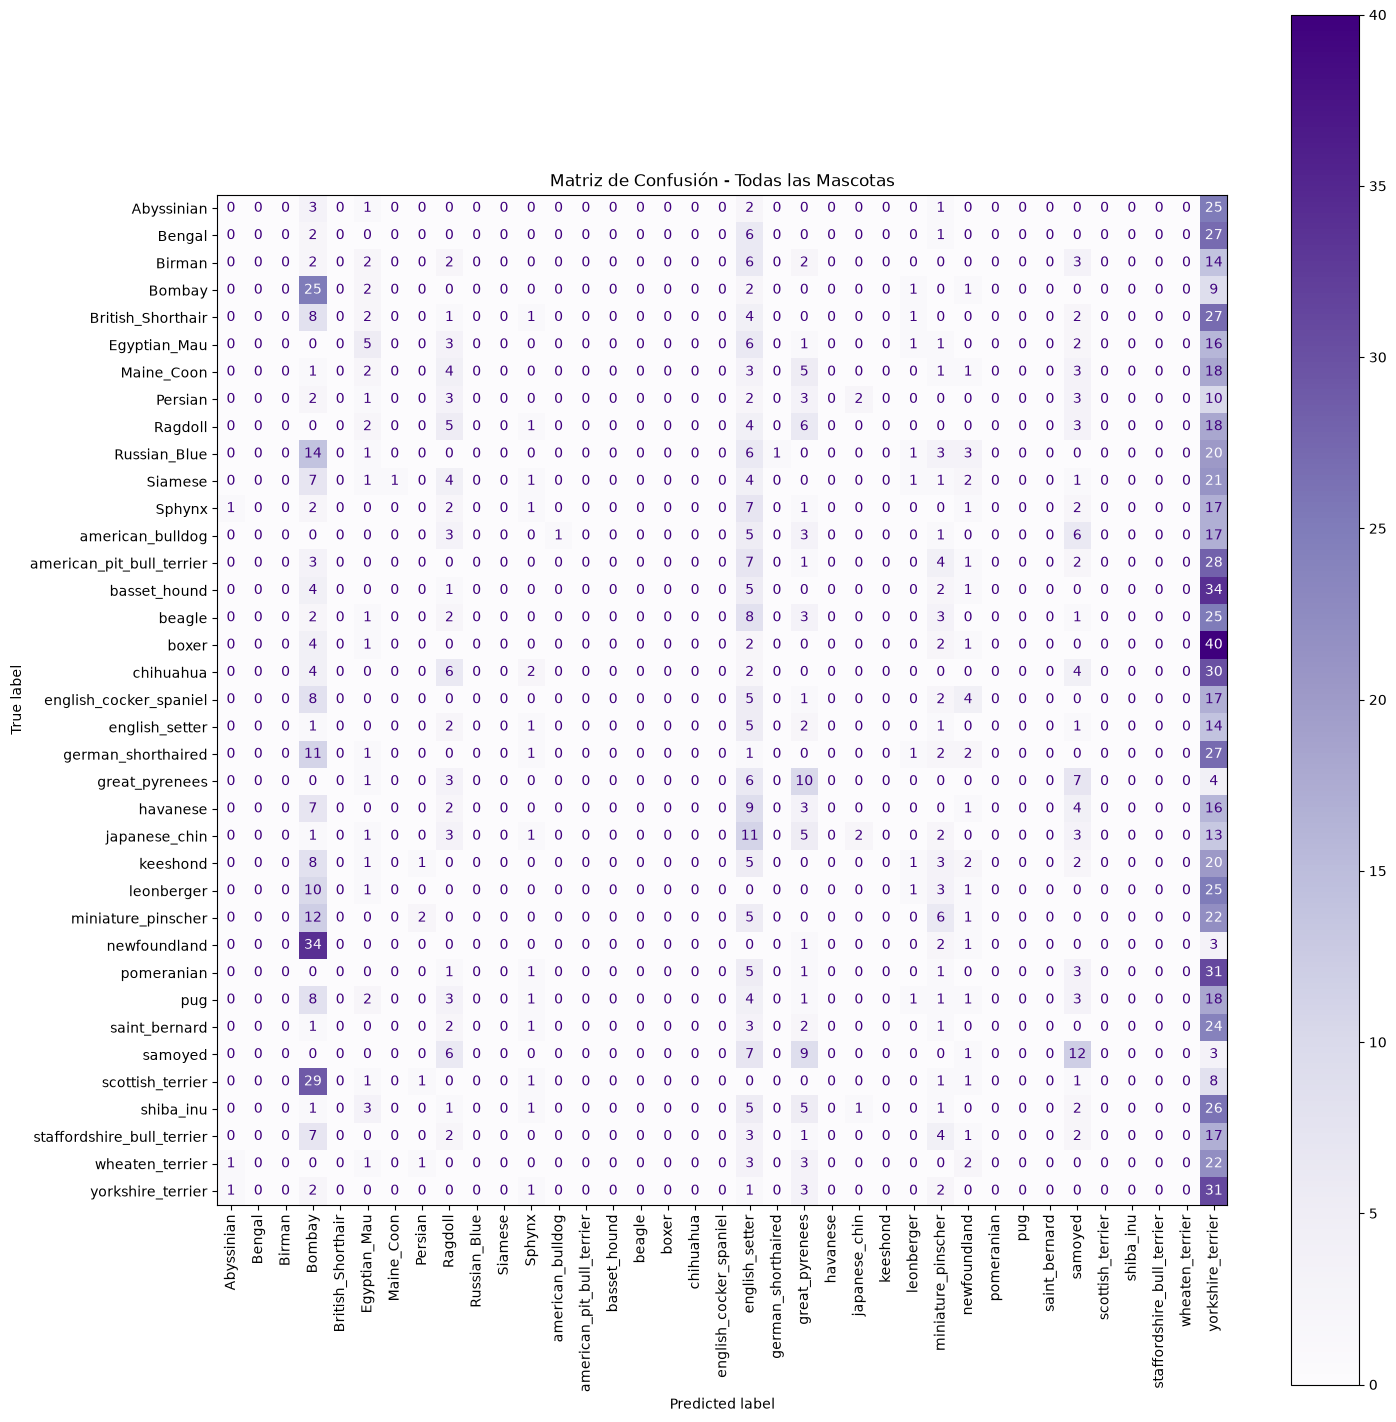

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. GRAFICAR LAS CURVAS DE APRENDIZAJE (Accuracy y Loss)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='Entrenamiento', marker='o')
plt.plot(historial.history['val_accuracy'], label='Validación', marker='o')
plt.title('Curva de Accuracy (Multiclase)')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='Entrenamiento', marker='o')
plt.plot(historial.history['val_loss'], label='Validación', marker='o')
plt.title('Curva de Loss (Error)')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show() # Guarda esta curva para el informe

# 2. GENERAR PREDICCIONES
print("\nGenerando predicciones en el set de validación...")
y_true = []
y_pred_probs = []

for images, labels in val_dataset:
    y_true.extend(labels.numpy())
    preds = modelo_mlp.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)

# ¡CAMBIO CLAVE! Para multiclase, elegimos la clase con la probabilidad más alta
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. REPORTE DE CLASIFICACIÓN
print("\n--- REPORTE DE CLASIFICACIÓN ---")
# Esto imprimirá el F1-Score para cada una de las razas
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

# 4. MATRIZ DE CONFUSIÓN GIGANTE
print("\n--- MATRIZ DE CONFUSIÓN ---")
cm = confusion_matrix(y_true, y_pred)
# Hacemos la figura muy grande para que quepan todos los nombres
fig, ax = plt.subplots(figsize=(15, 15)) 
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
# Usamos tonos morados (Purples) y ponemos los textos en vertical para que no se choquen
disp.plot(cmap=plt.cm.Purples, ax=ax, xticks_rotation='vertical')
plt.title("Matriz de Confusión - Todas las Mascotas")
plt.tight_layout()
plt.show()


--- EJEMPLOS CORRECTAMENTE CLASIFICADOS ---


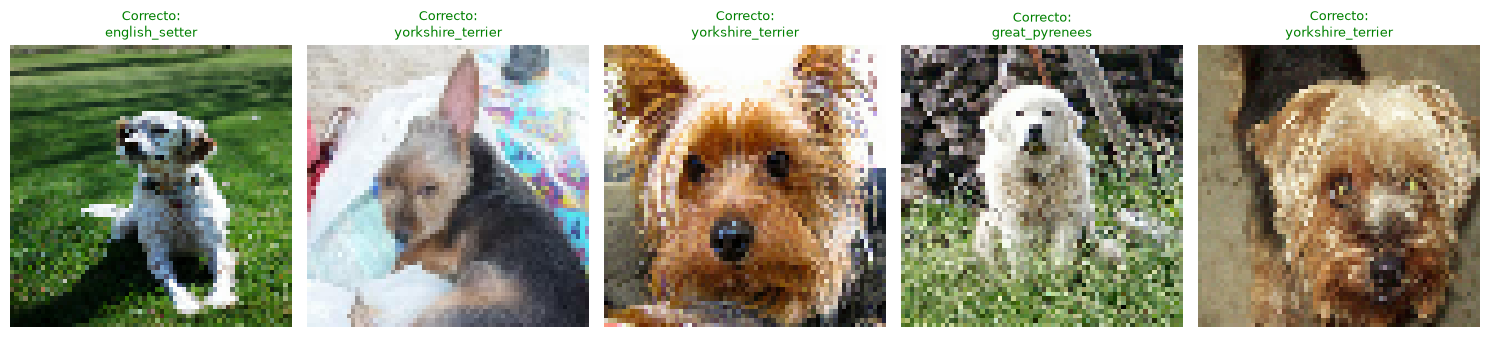


--- EJEMPLOS INCORRECTAMENTE CLASIFICADOS (ERRORES) ---


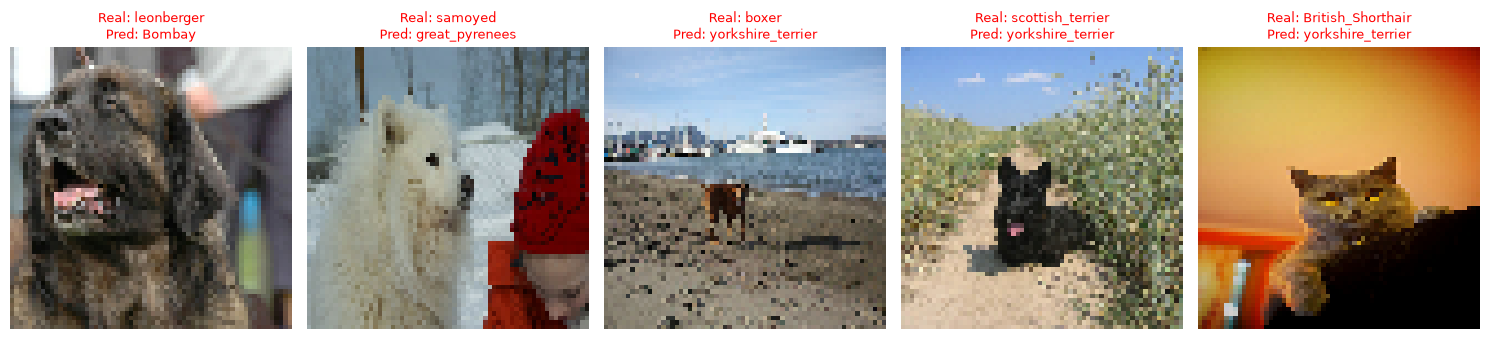


Guardando el modelo entrenado...
¡Modelo guardado exitosamente en la carpeta 'models'!


In [12]:
# 5. ANÁLISIS DE RESULTADOS: Ejemplos Correctos e Incorrectos
print("\n--- EJEMPLOS CORRECTAMENTE CLASIFICADOS ---")
plt.figure(figsize=(15, 4))
aciertos = 0

for images, labels in val_dataset:
    preds = modelo_mlp.predict(images, verbose=0)
    preds_clases = np.argmax(preds, axis=1) # Multiclase
    etiquetas_reales = labels.numpy()
    
    for i in range(len(etiquetas_reales)):
        if preds_clases[i] == etiquetas_reales[i]: 
            ax = plt.subplot(1, 5, aciertos + 1)
            plt.imshow(images[i].numpy())
            clase_real = class_names[etiquetas_reales[i]]
            plt.title(f"Correcto:\n{clase_real}", fontsize=9, color='green')
            plt.axis("off")
            aciertos += 1
        if aciertos == 5: break
    if aciertos == 5: break
plt.tight_layout()
plt.show()

print("\n--- EJEMPLOS INCORRECTAMENTE CLASIFICADOS (ERRORES) ---")
plt.figure(figsize=(15, 4))
errores = 0

for images, labels in val_dataset:
    preds = modelo_mlp.predict(images, verbose=0)
    preds_clases = np.argmax(preds, axis=1) # Multiclase
    etiquetas_reales = labels.numpy()
    
    for i in range(len(etiquetas_reales)):
        if preds_clases[i] != etiquetas_reales[i]: 
            ax = plt.subplot(1, 5, errores + 1)
            plt.imshow(images[i].numpy())
            clase_real = class_names[etiquetas_reales[i]]
            clase_pred = class_names[preds_clases[i]]
            plt.title(f"Real: {clase_real}\nPred: {clase_pred}", fontsize=9, color='red')
            plt.axis("off")
            errores += 1
        if errores == 5: break
    if errores == 5: break
plt.tight_layout()
plt.show() 

# 6. GUARDAR EL MODELO
print("\nGuardando el modelo entrenado...")
import os
if not os.path.exists('../models'):
    os.makedirs('../models') 

modelo_mlp.save('../models/modelo_mascotas_multiclase.keras')
print("¡Modelo guardado exitosamente en la carpeta 'models'!")